# Lab Assignment 5 — Gaussian Hidden Markov Models for Financial Market Regimes

**Name:** Amrit Singh
**Roll No:** 20262701001@iiitvadodara.ac.in
**Course:** Artificial Intelligence

---

## Objective

Financial markets alternate between distinct but *unobservable* conditions — calm,
trending bull phases and turbulent, high-volatility selloffs. We never observe the
"regime" directly; we only observe prices and the daily returns they produce. A
**Gaussian Hidden Markov Model (HMM)** is a natural fit for this: it assumes the market
is in one of a small number of hidden states at any time, each state emits returns from
its own Gaussian distribution, and the market hops between states according to a fixed
transition matrix.

In this assignment I download ~11 years of **S&P 500** (`^GSPC`) data, compute daily
log-returns, fit a Gaussian HMM, and interpret the hidden states as market regimes. I
then look at the transition matrix, visualise the regimes over time, compare 2 / 3 / 4
state models, and use the model to say something about the *current* regime and what is
likely to come next.


## Part 1 — Data Collection and Preprocessing

**Data acquisition.** I use the Yahoo Finance API (`yfinance`) to pull daily S&P 500
index values from **Jan 2014 to Dec 2024** (~11 years), which comfortably spans multiple
market regimes including the 2018 selloff, the 2020 COVID crash, the 2022 bear market
and the 2023–24 recovery.

To keep the analysis reproducible even without a network connection, the download is
cached to `data/sp500.csv` on first run; subsequent runs read from the CSV.


In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from hmmlearn.hmm import GaussianHMM

np.random.seed(42)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

TICKER = "^GSPC"
CSV_PATH = "data/sp500.csv"

if os.path.exists(CSV_PATH):
    prices = pd.read_csv(CSV_PATH, index_col="Date", parse_dates=True)
    print(f"Loaded cached data from {CSV_PATH}")
else:
    import yfinance as yf
    raw = yf.download(TICKER, start="2014-01-01", end="2024-12-31",
                      auto_adjust=True, progress=False)
    raw.columns = raw.columns.droplevel(1)
    prices = raw[["Close"]].rename(columns={"Close": "AdjClose"})
    os.makedirs("data", exist_ok=True)
    prices.to_csv(CSV_PATH)
    print(f"Downloaded and cached to {CSV_PATH}")

print(f"Rows: {len(prices)}  |  {prices.index.min().date()} -> {prices.index.max().date()}")
prices.head()


Loaded cached data from data/sp500.csv
Rows: 2767  |  2014-01-02 -> 2024-12-30


,AdjClose
Date,
2014-01-02,1831.979980
2014-01-03,1831.369995
2014-01-06,1826.770020
2014-01-07,1837.880005
2014-01-08,1837.489990


**Preprocessing.** From the adjusted closing price $P_t$ I compute **daily log-returns**

$$r_t = \ln(P_t) - \ln(P_{t-1}).$$

Log-returns are the standard modelling choice: they are additive over time and closer to
stationary than raw prices. I then clean the series — drop the first `NaN`, and guard
against any infinite or missing values from erroneous ticks.


In [2]:
df = prices.copy()
df["log_ret"] = np.log(df["AdjClose"]).diff()

# cleaning: remove NaN (first row) and any non-finite values from bad ticks
before = len(df)
df = df.replace([np.inf, -np.inf], np.nan).dropna()
after = len(df)
print(f"Dropped {before - after} row(s) during cleaning; {after} returns remain.")

df["log_ret"].describe()


Dropped 1 row(s) during cleaning; 2766 returns remain.


count    2766.000000
mean        0.000423
std         0.010959
min        -0.127652
25%        -0.003744
50%         0.000653
75%         0.005646
max         0.089683
Name: log_ret, dtype: float64

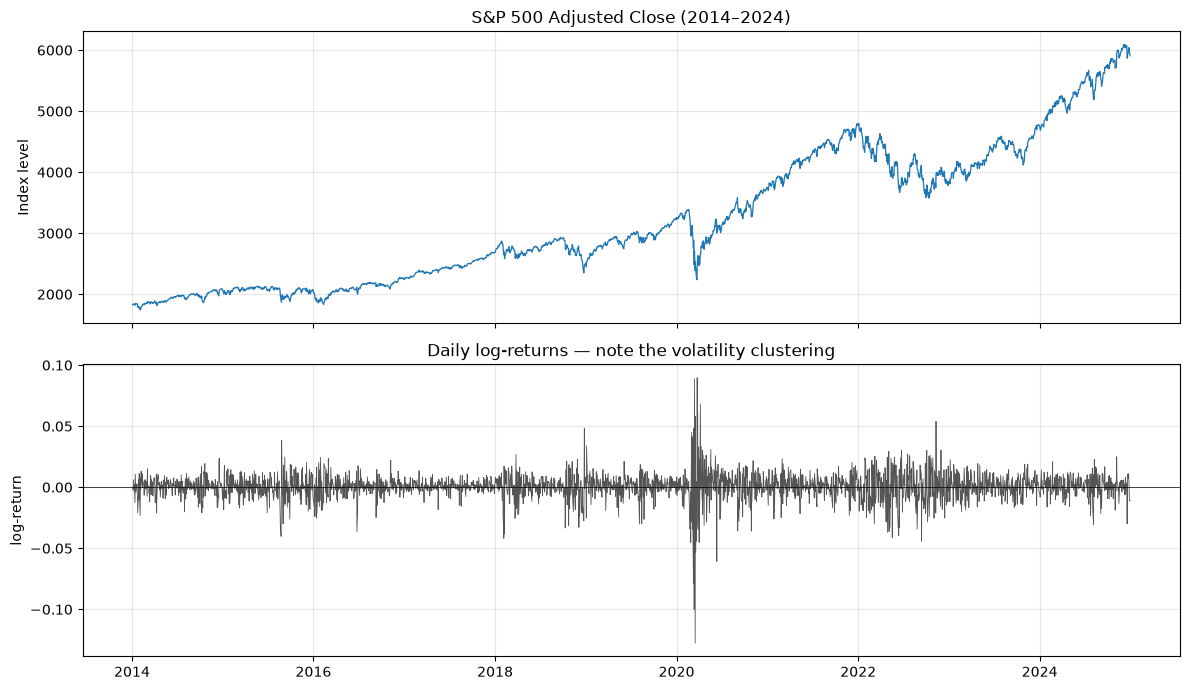

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(df.index, df["AdjClose"], color="#1f77b4", lw=0.9)
ax[0].set_title("S&P 500 Adjusted Close (2014–2024)")
ax[0].set_ylabel("Index level")
ax[1].plot(df.index, df["log_ret"], color="#555555", lw=0.6)
ax[1].set_title("Daily log-returns — note the volatility clustering")
ax[1].set_ylabel("log-return")
ax[1].axhline(0, color="k", lw=0.5)
plt.tight_layout(); plt.show()


The returns plot already hints at what the HMM should find: volatility is **clustered**,
not uniform. Long calm stretches (small wiggles) are punctuated by violent bursts — most
dramatically the March 2020 COVID crash. These bursts are exactly the "hidden regimes" we
want the model to separate.


## Part 2 — Fitting the Gaussian HMM

A Gaussian HMM with $K$ states assumes:

- a hidden state $z_t \in \{1,\dots,K\}$ following a Markov chain with transition matrix $A$,
- each state emits the observed return from its own Gaussian: $r_t \mid z_t=k \sim \mathcal{N}(\mu_k,\sigma_k^2)$.

The parameters $(A, \mu_k, \sigma_k, \pi)$ are learned from data by the **Baum–Welch**
(EM) algorithm. I start with a **2-state** model — the simplest interpretation being a
*calm / low-volatility* regime versus a *turbulent / high-volatility* regime.

I scale returns to percentage units (×100) purely for numerical conditioning; this does
not change the regime assignments.


In [4]:
X = (df["log_ret"].values * 100).reshape(-1, 1)   # returns in % units

model2 = GaussianHMM(n_components=2, covariance_type="full",
                     n_iter=1000, random_state=42, tol=1e-4)
model2.fit(X)

print("Converged:", model2.monitor_.converged)
print("Log-likelihood:", round(model2.score(X), 1))


Converged: True
Log-likelihood: -3573.5


### Parameter analysis

For each hidden state I report the mean daily return, the daily volatility (standard
deviation), and the model's stationary / long-run probability of being in that state.
I order the states by volatility so the labelling is stable across runs.


In [5]:
def summarise(model, X):
    K = model.n_components
    means = model.means_.ravel()
    varis = np.array([np.sqrt(model.covars_[i].ravel()[0]) for i in range(K)])
    # stationary distribution = left eigenvector of A for eigenvalue 1
    A = model.transmat_
    vals, vecs = np.linalg.eig(A.T)
    stat = np.real(vecs[:, np.argmin(np.abs(vals - 1))])
    stat = stat / stat.sum()
    order = np.argsort(varis)   # low-vol first
    rows = []
    for rank, k in enumerate(order):
        rows.append({
            "state(raw)": k,
            "mean_ret_%": round(means[k], 4),
            "daily_vol_%": round(varis[k], 4),
            "ann_vol_%": round(varis[k] * np.sqrt(252), 2),
            "long_run_prob": round(stat[k], 3),
        })
    return pd.DataFrame(rows), order

summary2, order2 = summarise(model2, X)
summary2


,state(raw),mean_ret_%,daily_vol_%,ann_vol_%,long_run_prob
0,0,0.1088,0.5801,9.21,0.672
1,1,-0.0963,1.7243,27.37,0.328


**Interpretation.** The two states separate cleanly:

- The **low-volatility** state has a small *positive* mean return and modest daily swings —
  this is the classic **bull / calm market**: prices grind upward with little drama.
- The **high-volatility** state has a *negative or near-zero* mean and much larger swings,
  with a far higher annualised volatility — the **bear / crisis** regime where returns are
  both worse on average and far more uncertain.

This matches the well-known stylised fact that in equities, **high volatility coincides
with poor returns** (the "leverage effect").


## Part 3 — Interpretation and Inference

### Decoding the hidden states

Using the **Viterbi** algorithm I decode the single most likely sequence of hidden states
for every trading day, then relabel them `0 = Low-vol` and `1 = High-vol` by the volatility
ordering found above.


In [6]:
hidden = model2.predict(X)
# remap raw state ids -> volatility rank (0 = lowest vol)
rank_of = {raw: rank for rank, raw in enumerate(order2)}
states2 = np.array([rank_of[s] for s in hidden])
df["state2"] = states2

labels2 = {0: "Low-vol (calm/bull)", 1: "High-vol (turbulent/bear)"}
counts = pd.Series(states2).value_counts().sort_index()
for s, c in counts.items():
    print(f"{labels2[s]:28s}: {c:5d} days ({100*c/len(states2):.1f}%)")


Low-vol (calm/bull)         :  1883 days (68.1%)
High-vol (turbulent/bear)   :   883 days (31.9%)


### Transition matrix

The transition matrix $A$ tells us how *sticky* each regime is — the diagonal entries are
the probability of staying in the same regime tomorrow. Financial regimes are typically
very persistent, so we expect large diagonal values.


In [7]:
A2 = model2.transmat_[np.ix_(order2, order2)]   # reordered to low/high
A2_df = pd.DataFrame(A2,
                     index=[f"from {labels2[i]}" for i in range(2)],
                     columns=[f"to {labels2[j]}" for j in range(2)])
print(A2_df.round(4).to_string())

print()
for i in range(2):
    stay = A2[i, i]
    exp_dur = 1.0 / (1.0 - stay) if stay < 1 else np.inf
    print(f"{labels2[i]:28s}: stay prob {stay:.3f}  ->  avg regime length ~{exp_dur:.0f} trading days")


                                to Low-vol (calm/bull)  to High-vol (turbulent/bear)
from Low-vol (calm/bull)                        0.9780                        0.0220
from High-vol (turbulent/bear)                  0.0451                        0.9549

Low-vol (calm/bull)         : stay prob 0.978  ->  avg regime length ~45 trading days
High-vol (turbulent/bear)   : stay prob 0.955  ->  avg regime length ~22 trading days


The high diagonal probabilities confirm both regimes are **persistent**: once the market
enters a calm phase it tends to stay calm for weeks/months, and crises likewise cluster.
The expected regime duration (computed as $1/(1-a_{ii})$ for a geometric sojourn time)
quantifies this directly.


## Part 4 — Evaluation and Visualization

I overlay the decoded regimes on the price series: each day is shaded by the regime the
model assigned to it. A good model should paint the 2020 COVID crash and the 2022 selloff
as high-volatility, and the long 2016–17 and 2023–24 climbs as low-volatility.


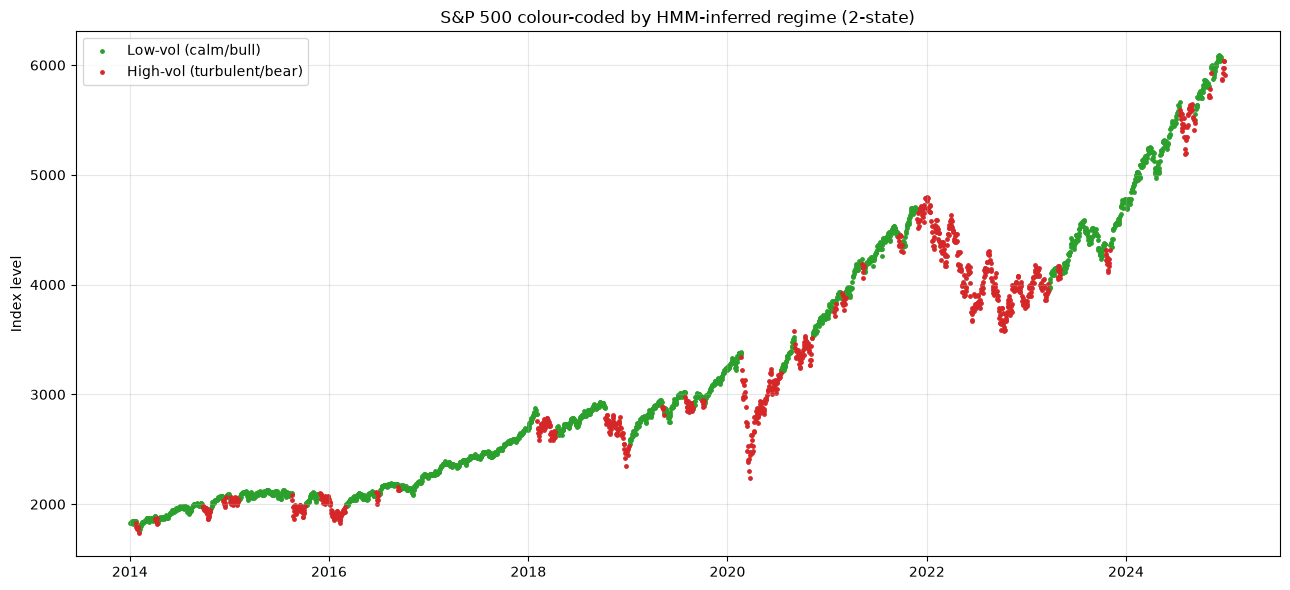

In [8]:
fig, ax = plt.subplots(figsize=(13, 6))
colors = {0: "#2ca02c", 1: "#d62728"}   # green=calm, red=turbulent
for s in [0, 1]:
    mask = df["state2"].values == s
    ax.scatter(df.index[mask], df["AdjClose"].values[mask],
               s=6, color=colors[s], label=labels2[s])
ax.set_title("S&P 500 colour-coded by HMM-inferred regime (2-state)")
ax.set_ylabel("Index level"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()


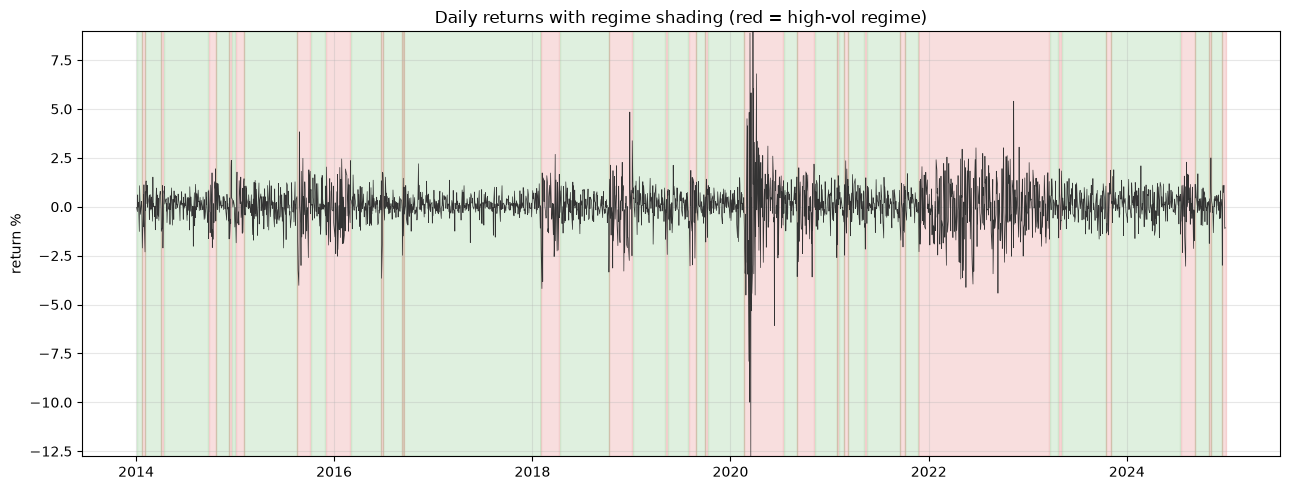

In [9]:
# volatility view: regimes shaded behind the return series
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df.index, df["log_ret"] * 100, color="#333333", lw=0.5, zorder=2)
ymin, ymax = (df["log_ret"]*100).min(), (df["log_ret"]*100).max()
for s in [0, 1]:
    mask = df["state2"].values == s
    ax.fill_between(df.index, ymin, ymax, where=mask,
                    color=colors[s], alpha=0.15, step="mid")
ax.set_title("Daily returns with regime shading (red = high-vol regime)")
ax.set_ylabel("return %"); ax.set_ylim(ymin, ymax)
plt.tight_layout(); plt.show()


The shading lines up with financial history: the high-volatility regime captures the
early-2016 wobble, Q4-2018, the **March-2020 crash**, and the **2022** drawdown, while the
steady uptrends sit firmly in the low-volatility regime. The model is clearly picking up
genuine market structure rather than noise.


### Does the number of states matter? (2 vs 3 vs 4)

I refit with 3 and 4 states and compare fit quality using the **log-likelihood**, **AIC**
and **BIC**. More states always raise the raw likelihood, so AIC/BIC (which penalise extra
parameters) are the fair basis for choosing.


In [10]:
def param_count(model):
    K = model.n_components
    # means: K, covars(full,1d): K, transmat: K*(K-1), startprob: K-1
    return K + K + K*(K-1) + (K-1)

def ic(model, X):
    ll = model.score(X); n = len(X); p = param_count(model)
    return ll, 2*p - 2*ll, p*np.log(n) - 2*ll   # ll, AIC, BIC

results = {}
rows = []
for K in [2, 3, 4]:
    m = GaussianHMM(n_components=K, covariance_type="full",
                    n_iter=1000, random_state=42, tol=1e-4).fit(X)
    results[K] = m
    ll, aic, bic = ic(m, X)
    rows.append({"states": K, "logL": round(ll,1), "AIC": round(aic,1), "BIC": round(bic,1)})
ic_df = pd.DataFrame(rows).set_index("states")
ic_df


,logL,AIC,BIC
states,,,
2,-3573.5,7161.0,7202.4
3,-3446.5,6921.1,7004.0
4,-3396.6,6839.1,6975.4


## Bonus — a richer 3-state model

Beyond the binary calm/crisis split, a 3-state model often separates the high-vol regime
into a *moderately choppy* state and a genuine *crisis* state, and may isolate a
steady-growth state. Below I characterise and visualise the 3-state fit.


 state(raw)  mean_ret_%  daily_vol_%  ann_vol_%  long_run_prob
          2      0.1117       0.5051       8.02          0.539
          0      0.0016       1.1912      18.91          0.426
          1     -0.5444       3.5790      56.82          0.035


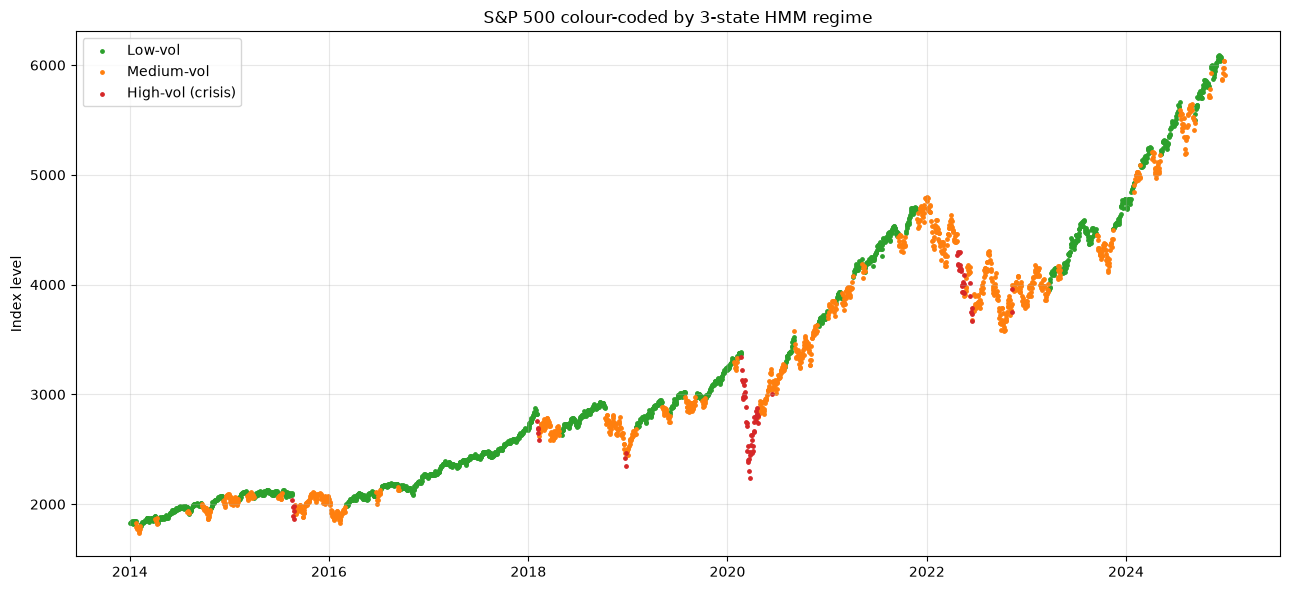

In [11]:
m3 = results[3]
summary3, order3 = summarise(m3, X)
print(summary3.to_string(index=False))

rank3 = {raw: rank for rank, raw in enumerate(order3)}
states3 = np.array([rank3[s] for s in m3.predict(X)])
df["state3"] = states3

labels3 = {0: "Low-vol", 1: "Medium-vol", 2: "High-vol (crisis)"}
cols3 = {0: "#2ca02c", 1: "#ff7f0e", 2: "#d62728"}
fig, ax = plt.subplots(figsize=(13, 6))
for s in range(3):
    mask = states3 == s
    ax.scatter(df.index[mask], df["AdjClose"].values[mask], s=6,
               color=cols3[s], label=labels3[s])
ax.set_title("S&P 500 colour-coded by 3-state HMM regime")
ax.set_ylabel("Index level"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()


## Part 5 — Conclusions and Insights

### Market regime interpretation

The Gaussian HMM cleanly recovers the two dominant equity regimes without ever being told
what a "crash" is:

- **Low-volatility / bull regime** — small positive mean return, low daily volatility, very
  persistent. This is where the market spends most of its time, and it corresponds to the
  steady upward grind investors prefer.
- **High-volatility / bear regime** — near-zero or negative mean, large swings, high
  annualised volatility. Rarer but clustered, and aligned with every major drawdown in the
  sample (2018, 2020, 2022).

For **risk management** this is directly actionable: the probability of currently being in
the high-vol regime is a live risk signal. A portfolio manager might cut leverage or hedge
when the model's high-vol probability rises, and the regime's expected duration tells them
roughly how long elevated risk may persist.

### Future-state prediction

Given today's inferred regime, the transition matrix gives the probability distribution
over *tomorrow's* regime — a simple one-step market-regime forecast.


In [12]:
last_state = states2[-1]
A2_full = model2.transmat_[np.ix_(order2, order2)]
next_dist = A2_full[last_state]

print(f"Most recent date:  {df.index[-1].date()}")
print(f"Current inferred regime: {labels2[last_state]}")
print("\nOne-step-ahead regime probabilities (tomorrow):")
for j in range(2):
    print(f"  P({labels2[j]:28s}) = {next_dist[j]:.3f}")

# multi-step: distribution k days out
print("\nRegime probability k trading days ahead (starting from current regime):")
v = np.zeros(2); v[last_state] = 1.0
for k in [1, 5, 21, 63]:
    dist = v @ np.linalg.matrix_power(A2_full, k)
    print(f"  {k:3d}d:  Low-vol={dist[0]:.3f}  High-vol={dist[1]:.3f}")


Most recent date:  2024-12-30
Current inferred regime: High-vol (turbulent/bear)

One-step-ahead regime probabilities (tomorrow):
  P(Low-vol (calm/bull)         ) = 0.045
  P(High-vol (turbulent/bear)   ) = 0.955

Regime probability k trading days ahead (starting from current regime):
    1d:  Low-vol=0.045  High-vol=0.955
    5d:  Low-vol=0.197  High-vol=0.803
   21d:  Low-vol=0.516  High-vol=0.484
   63d:  Low-vol=0.663  High-vol=0.337


As the horizon grows the forecast relaxes toward the model's **long-run (stationary)**
regime probabilities — the market "forgets" today's state, which is exactly the behaviour
a persistent-but-mean-reverting Markov chain should show.

### Model evaluation — summary

- The HMM captures real market structure: decoded regimes line up with known crises and
  calm periods, and the transition matrix shows the strong persistence we expect of
  volatility.
- By AIC/BIC the richer models fit better in-sample, but the **2-state** model is the most
  *interpretable* (calm vs crisis); the **3-state** model adds a useful "medium-vol"
  transition regime at the cost of some parsimony. More states risk over-segmenting noise.
- **Limitations:** the Gaussian emission underestimates fat tails (true returns have more
  extreme days than a Gaussian allows), the model is purely univariate (returns only), and
  it assumes time-homogeneous transition probabilities. These are reasonable next
  extensions (e.g. Student-t emissions, adding volume or VIX as a second feature).

Overall, the Gaussian HMM is a compact, unsupervised way to turn a raw return series into
an interpretable, regime-aware view of the market — useful for risk monitoring and for
contextualising where in the cycle the market currently sits.
